# Analisi iniziale dei dati

## Evoluzione delle anime negli anni

In [21]:
import pandas as pd
from matplotlib import pyplot as plt
import seaborn as sns
import numpy as np
import plotly.graph_objects as go
import ast
import plotly.express as px

In [22]:
# load dataset
df_details = pd.read_csv("../../dataset/cleaned/details_cleaned.csv")
df_favs = pd.read_csv("../../dataset/cleaned/favs_cleaned.csv")
df_recommendations = pd.read_csv("../../dataset/cleaned/recommendations_cleaned.csv")
df_stats = pd.read_csv("../../dataset/cleaned/stats_cleaned.csv")
df_ratings = pd.read_csv("../../dataset/cleaned/ratings_cleaned.csv")


In [23]:
df_details['start_date'] = pd.to_datetime(df_details['start_date'], errors='coerce')
df_details['year'] = df_details['start_date'].dt.year.astype("Int64")
df_details['scored_by'] = pd.to_numeric(df_details['scored_by'], errors='coerce')

### Nella prima parte viene presentata un’analisi temporale della produzione, utile a contestualizzare storicamente il fenomeno. Le sezioni successive approfondiscono aspetti legati alla popolarità, ai rating degli utenti e alle fonti di ispirazione

In [24]:
details = df_details.copy()
details = details.dropna(subset=['start_date'])

# Conteggio anime per anno
counts = (details['year'].value_counts().sort_index().reset_index())
counts.columns = ['year', 'anime_count']

fig = px.line(counts,x='year',y='anime_count',markers=True,
    title="Numero di anime per anno di inizio",
    labels={'year': 'Anno di inizio','anime_count': 'Numero di anime'},
    hover_data={'year': True,'anime_count': True})
fig.update_traces(marker=dict(size=5),line=dict(width=2))
fig.update_layout(
    xaxis=dict(range=[1917, 2024]),
    hovermode="x unified",
    template="plotly_dark",
    title_font_size=14
)
fig.show()

Dagli anni ’70 in poi si osserva una **crescita** quasi **esponenziale** del numero di anime prodotti, con un’accelerazione marcata dopo il 2000.
Negli ultimi anni, invece, il trend mostra oscillazioni e un leggero **calo**, suggerendo una possibile fase di saturazione del mercato.

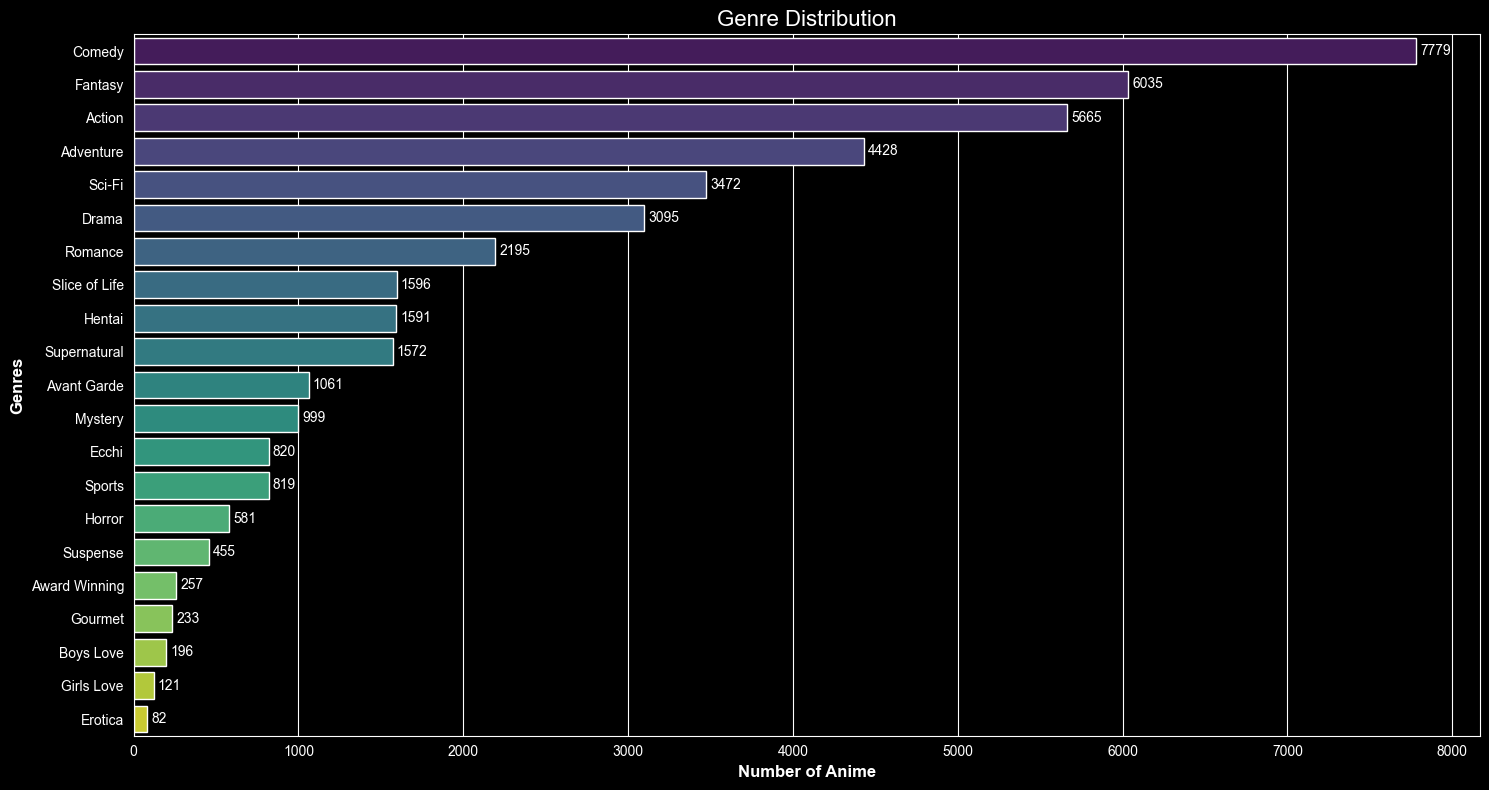

In [25]:
df_genres = df_details['genres'].copy()
df_genres = df_genres.apply(ast.literal_eval)

df_genres = df_genres.explode().dropna()
genre_count = df_genres.value_counts().reset_index()

genre_count.columns = ['genre', 'count']
# plot
plt.figure(figsize=(15, 8))
ax = sns.barplot(data=genre_count, x='count', y='genre', hue='genre', palette='viridis')
for container in ax.containers:
    ax.bar_label(container, padding=3)

plt.title('Genre Distribution', fontsize=16)
plt.xlabel('Number of Anime', fontsize=12, fontweight='bold')
plt.ylabel('Genres', fontsize=12, fontweight='bold')

plt.tight_layout()
plt.show()


## Evoluzione dei principali generi anime nel tempo

### Come cambiano i generi anime dal 1917 a oggi

In [26]:
def parse_genres(x):
    if isinstance(x, list):
        return x
    try:
        return ast.literal_eval(x)
    except:
        return []

In [27]:
df_gen_evol = df_details.copy()
df_gen_evol = df_gen_evol.dropna(subset=['year'])

df_gen_evol = df_gen_evol[(df_gen_evol['year'] >= 1917) & (df_gen_evol['year'] <= 2024)]
df_gen_evol = df_gen_evol.dropna(subset=['genres'])
df_gen_evol['genres'] = df_gen_evol['genres'].apply(parse_genres)
df_gen_evol['genres'] = df_gen_evol['genres'].apply(lambda g: [gen.strip().title() for gen in g])

# explode generi
genres_df = df_gen_evol.explode('genres')
# conteggio per anno e genere
genre_year = (genres_df.groupby(['year', 'genres']).size() .reset_index(name='count'))
# grafico
fig = go.Figure()
for genre in sorted(genre_year['genres'].unique()):
    df_g = genre_year[genre_year['genres'] == genre]
    fig.add_trace(
        go.Scatter(
            x=df_g['year'],
            y=df_g['count'],
            mode='lines',
            name=genre,
            visible='legendonly'
        )
    )
fig.update_layout(
    title="Anime production over time by genre",
    xaxis_title="Year",
    yaxis_title="Number of anime released",
    template="plotly_dark",
    hovermode="x unified",
    legend_title="Click genres to show / hide"
)
fig.show()

Questo grafico mostra l’evoluzione dei principali generi anime nel tempo, evidenziando come la crescita dell’industria sia stata accompagnata da una progressiva specializzazione dei contenuti.

Fino agli anni ’80 la produzione è limitata e relativamente omogenea, mentre a partire dagli anni ’90 emergono differenze sempre più marcate tra i generi.

Dopo il 2000 si osserva una forte espansione di generi come **Action**, **Fantasy** e **Comedy**, riflettendo l’ampliamento del pubblico e la diversificazione dei gusti.

Negli anni più recenti alcune curve mostrano una stabilizzazione o una lieve flessione, suggerendo una fase di assestamento del mercato più che una diminuzione di interesse

#### Ok, abbiamo visto come cambiano le cose nel tempo. Ora guardiamo com’è fatto l’ecosistema complessivo.

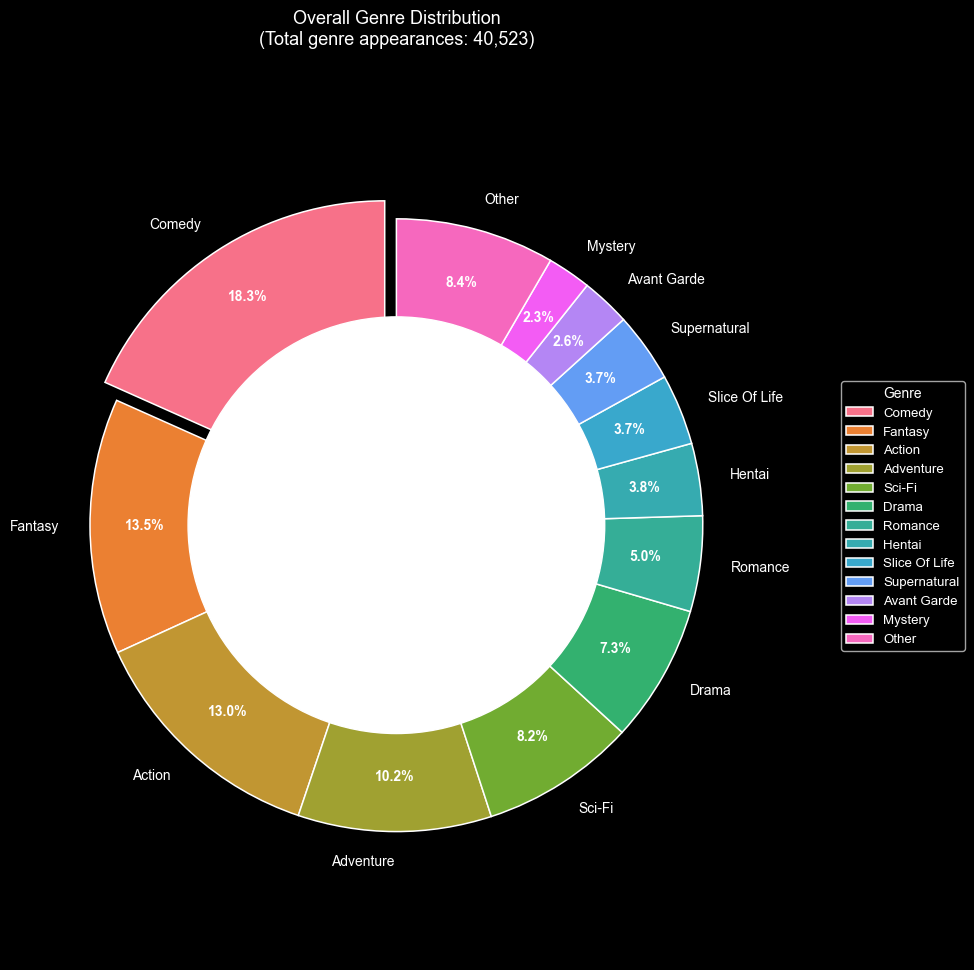

In [28]:
# conta quante volte compare ogni genere
genre_total = genres_df['genres'].value_counts()
# numeri di generi principali da mostrare singolarmente nel pie
top_n_pie = 12
# prendiamo solo i primi N generi più frequentati
top_genres_pie = genre_total.head(top_n_pie)
# sommiamo tutti i generi rimnenti , ciè dal 13 e in poi
other_count = genre_total.iloc[top_n_pie:].sum()
# creiamo la categoria "other"
if other_count > 0:
    pie_data = pd.concat([
        top_genres_pie,
        pd.Series({'Other': other_count})
    ])
else:
    pie_data = top_genres_pie
# creazione grafico
plt.figure(figsize=(10, 10))
colors = sns.color_palette("husl", len(pie_data))
# explode solo sulla fetta più frequente
explode = [0.07 if genre == pie_data.idxmax() else 0 for genre in pie_data.index]
# disegno pie chart
wedges, texts, autotexts = plt.pie(
    pie_data.values,
    labels=pie_data.index,
    autopct='%1.1f%%',
    startangle=90,
    colors=colors,
    explode=explode,
    pctdistance=0.82,
    wedgeprops={'edgecolor': 'white', 'linewidth': 1.1},
    textprops={'fontsize': 10}
)
# stile delle percentuali
for autotext in autotexts:autotext.set_color('white'), autotext.set_fontweight('bold')
# titoli
plt.title(f"Overall Genre Distribution\n(Total genre appearances: {genre_total.sum():,})",fontsize=13, pad=20)
# cerchio centrale per effetto 'donut'
centre_circle = plt.Circle((0, 0), 0.68, fc='white')
fig = plt.gcf()
fig.gca().add_artist(centre_circle)
# legenda
plt.legend(pie_data.index,title="Genre",loc="center left",bbox_to_anchor=(1.15, 0.5),fontsize=9.5)

plt.axis('equal')
plt.tight_layout()
plt.show()

I risultati evidenziano una forte predominanza di generi orientati all’intrattenimento di massa, come Comedy, Action e Fantasy, che rappresentano una parte significativa della produzione totale.

Accanto a questi, emerge una varietà di generi meno rappresentati che contribuiscono alla diversificazione dell’offerta, suggerendo un ecosistema ricco e stratificato piuttosto che dominato da una singola tendenza.

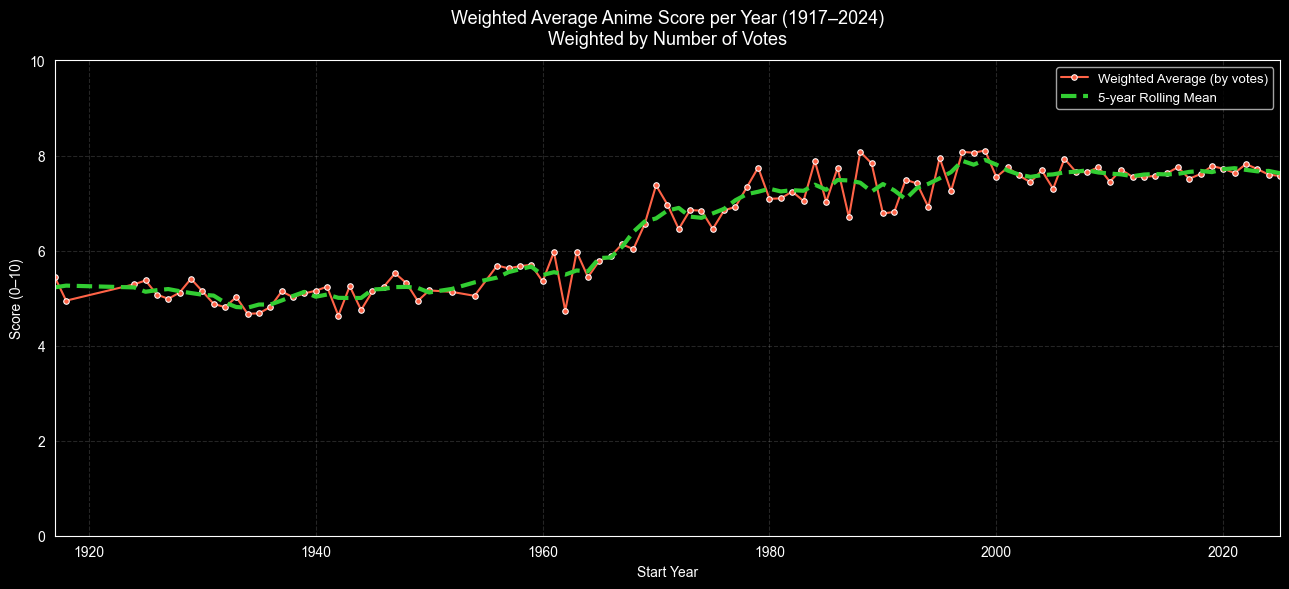

In [29]:
details = df_details.copy()
# filtro per il calcolo della media pesata
df_weighted = details[
    details['score'].notna() &
    details['scored_by'].notna() &
    (details['scored_by'] > 0) &
    details['year'].notna()
].copy()

# limitiamo l'analisi agli anni con dati storicamnete rilevanti
df_weighted = df_weighted[df_weighted['year'] >= 1917]

# calcolo di media dei punteggi, totale dei voti, numero di anime rilasciati
year_weighted = df_weighted.groupby('year', group_keys=False).apply(
    lambda x: pd.Series({
        'weighted_mean': (x['score'] * x['scored_by']).sum() / x['scored_by'].sum(),
        'total_votes': x['scored_by'].sum(),
        'anime_count': len(x)
    }),
    include_groups=False
).reset_index()
# Ordina per sicurezza
year_weighted = year_weighted.sort_values('year')
# calcoliamo una media mobile centrata su 5 anni per rendere il trend più leggibile
year_weighted['rolling_weighted'] = year_weighted['weighted_mean'].rolling(window=5, center=True, min_periods=2).mean()
# visualizzazione
plt.figure(figsize=(13, 6))
# Linea principale: media pesata
sns.lineplot(data=year_weighted,x='year',y='weighted_mean',color='tomato',linewidth=1.5,marker='o',markersize=4,label='Weighted Average (by votes)')
# media mobile
plt.plot(
    year_weighted['year'],
    year_weighted['rolling_weighted'],
    color='limegreen',
    linewidth=3,
    linestyle='--',
    label='5-year Rolling Mean'
)
plt.title("Weighted Average Anime Score per Year (1917–2024)\nWeighted by Number of Votes",fontsize=13,pad=12)
plt.xlabel("Start Year")
plt.ylabel("Score (0–10)")
# limiti degli assi per una scala coerente
plt.xlim(year_weighted['year'].min(), year_weighted['year'].max())
plt.ylim(0, 10)

plt.grid(True, alpha=0.15, linestyle='--')
plt.legend(fontsize=9.5)
plt.tight_layout()
plt.show()

Il grafico mostra l’andamento del punteggio medio degli anime dal 1917 al 2024, calcolato come media pesata sul numero di voti, così da dare maggiore importanza ai titoli più rilevanti per il pubblico.

Nei primi decenni la qualità media si mantiene su valori bassi e stabili, riflettendo una fase iniziale e sperimentale dell’industria. A partire dagli anni ’60 si osserva invece una crescita progressiva e significativa, in parallelo allo sviluppo dell’anime moderno e al consolidamento degli studi di animazione.

Dagli anni ’90 in poi, il punteggio medio raggiunge valori elevati e tende a stabilizzarsi, come evidenziato dalla media mobile a 5 anni. Questo suggerisce che, nonostante l’aumento della produzione, la qualità percepita dagli utenti rimane costante nel tempo, indicando una fase di maturità dell’industria anime.


### I generi più prodotti sono anche quelli più amati dai fan?

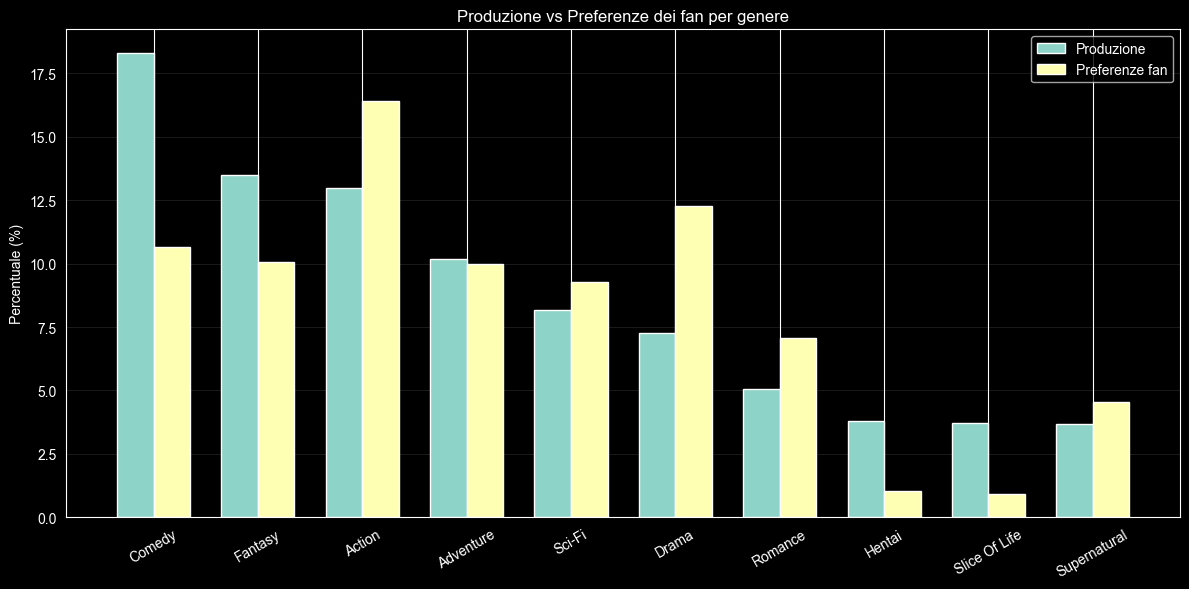

In [30]:
favs = df_favs.copy()
production = genres_df['genres'].value_counts()
production_pct = production / production.sum() * 100

favs_genres = pd.merge(favs, genres_df[['mal_id', 'genres']], on='mal_id', how='inner')
favs_count = favs_genres['genres'].value_counts()
favs_pct = favs_count / favs_count.sum() * 100

compare = pd.DataFrame({'Production (%)': production_pct, 'Fan Preferences (%)': favs_pct}).dropna()
compare = compare.sort_values('Production (%)', ascending=False).head(10)

x = np.arange(len(compare))
width = 0.35

plt.figure(figsize=(12, 6))
plt.bar(x - width / 2, compare['Production (%)'], width, label='Produzione')
plt.bar(x + width / 2, compare['Fan Preferences (%)'], width, label='Preferenze fan', )
plt.xticks(x, compare.index, rotation=30)
plt.ylabel("Percentuale (%)")
plt.title("Produzione vs Preferenze dei fan per genere")
plt.legend()
plt.grid(axis='y', alpha=0.1)
plt.tight_layout()
plt.show()

Il confronto tra la quota di produzione e le preferenze dei fan evidenzia come le strategie dell’industria anime non siano sempre allineate con i gusti del pubblico.
Mentre generi come Action mostrano un equilibrio tra offerta e domanda, altri come Comedy risultano sovra-rappresentati.
Al contrario, generi come Drama e Romance sembrano essere sottovalutati dall’industria nonostante un forte interesse da parte dei fan.

## Da dove nascono gli anime? Le fonti di ispirazione dell’industria

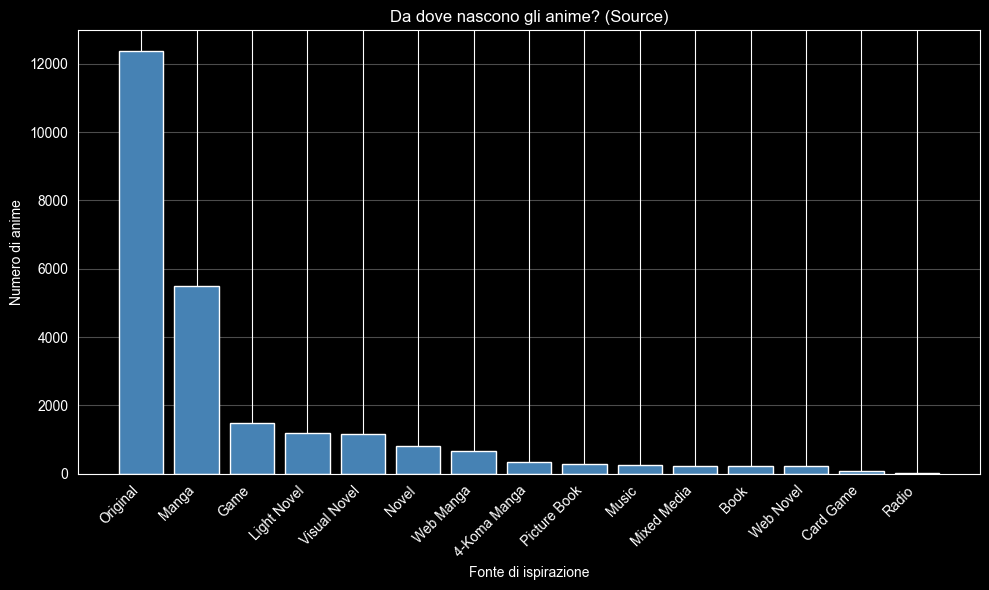

In [31]:
details = df_details.copy()
# filtro categoria unknown
details = details[(details['source'].notna()) & (details['source'] != 'Unknown') & (details['source'] != 'Other')]
details['source'] = details['source'].str.strip().str.title()
source_counts = (details['source'].value_counts().reset_index())
source_counts.columns = ['source', 'count']
# grafico
plt.figure(figsize=(10, 6))
plt.bar(source_counts['source'], source_counts['count'],color='steelblue')

plt.xlabel("Fonte di ispirazione")
plt.ylabel("Numero di anime")
plt.title("Da dove nascono gli anime? (Source)")

plt.xticks(rotation=45, ha='right')
plt.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

Il grafico mostra la distribuzione delle principali **fonti di ispirazione** degli anime, evidenziando da quali media o opere originali nasce la produzione animata giapponese.

Il dato più evidente è la **forte predominanza delle opere Original**, che rappresentano la quota maggiore. Questo suggerisce che l’industria anime mantiene una notevole capacità creativa autonoma, producendo contenuti non direttamente derivati da altri media.

Subito dopo emergono gli adattamenti da **Manga**, che confermano il ruolo centrale di questo medium come serbatoio narrativo per l’animazione giapponese. Manga e anime risultano quindi profondamente interconnessi, sia dal punto di vista artistico che industriale.

Le altre categorie (come **Light Novel**, **Game**, **Visual Novel** e **Web Manga**) hanno una presenza più contenuta ma significativa, indicando una crescente tendenza alla contaminazione tra media diversi. Questo fenomeno riflette l’evoluzione del consumo culturale, sempre più crossmediale.

Nel complesso, il grafico racconta un’industria che combina **creatività originale** e **adattamento strategico**, bilanciando innovazione e sicurezza commerciale.


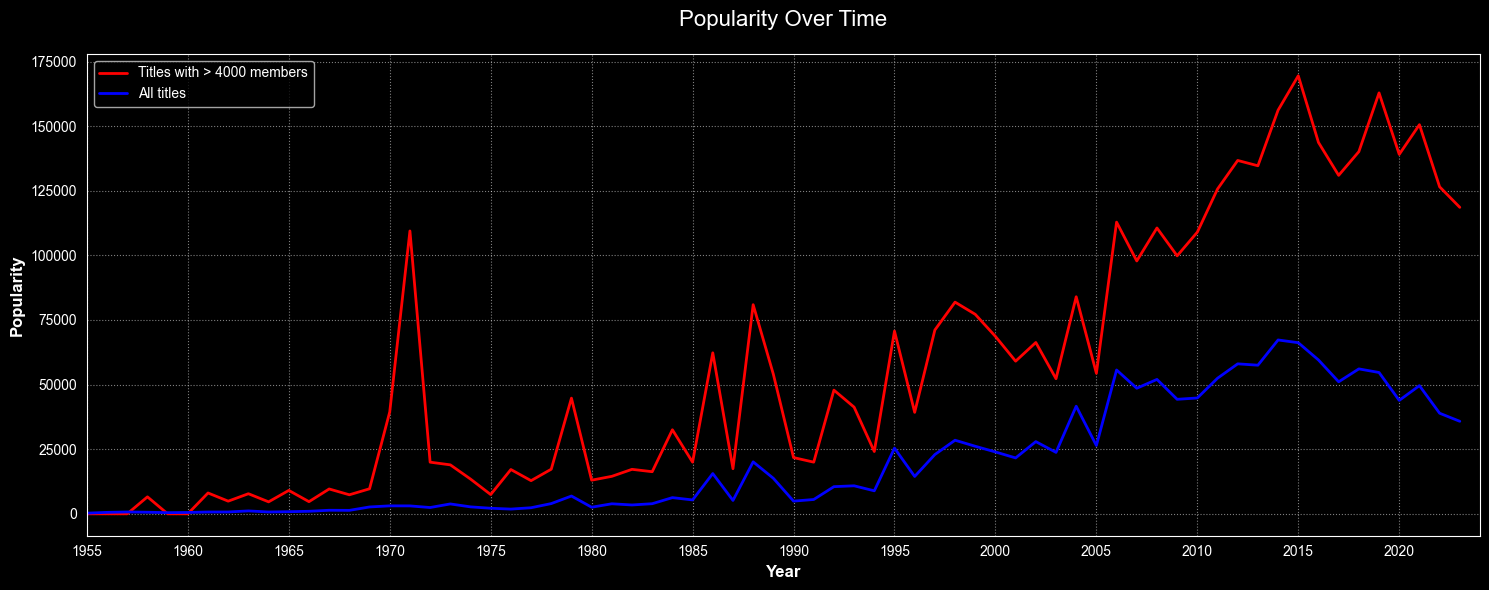

In [32]:
details = df_details.copy()
# popolarità media totale
all_members = (
    details.groupby('year')['members']
    .mean()
    .reindex(range(1955, 2024), fill_value=0)
    .reset_index()
    .rename(columns={'members': 'avg_members'})
)
# popolarità media filtrata
filtered_members = details[details['members'] > 4000]
filtered_members = (
    filtered_members.groupby('year')['members']
    .mean()
    .reindex(range(1955, 2024), fill_value=0)
    .reset_index()
    .rename(columns={'members': 'avg_members'})
)
# creazione grafico
plt.figure(figsize=(15, 6))
plt.grid(linestyle=':', alpha=0.5)
# linee
plt.plot(
    filtered_members['year'],
    filtered_members['avg_members'],
    color='red',
    linewidth=2,
    label='Titles with > 4000 members'
)
plt.plot(
    all_members['year'],
    all_members['avg_members'],
    color='blue',
    linewidth=2,
    label='All titles'
)
# personalizzazione assi
plt.title('Popularity Over Time', fontsize=16, pad=20)
plt.xlabel('Year', fontsize=12, fontweight='bold')
plt.ylabel('Popularity', fontsize=12, fontweight='bold')
plt.xlim(1955, 2024)
plt.xticks(range(1955, 2025, 5))
# legenda
plt.legend()

plt.tight_layout()
plt.show()


Top anime più amati dagli fan

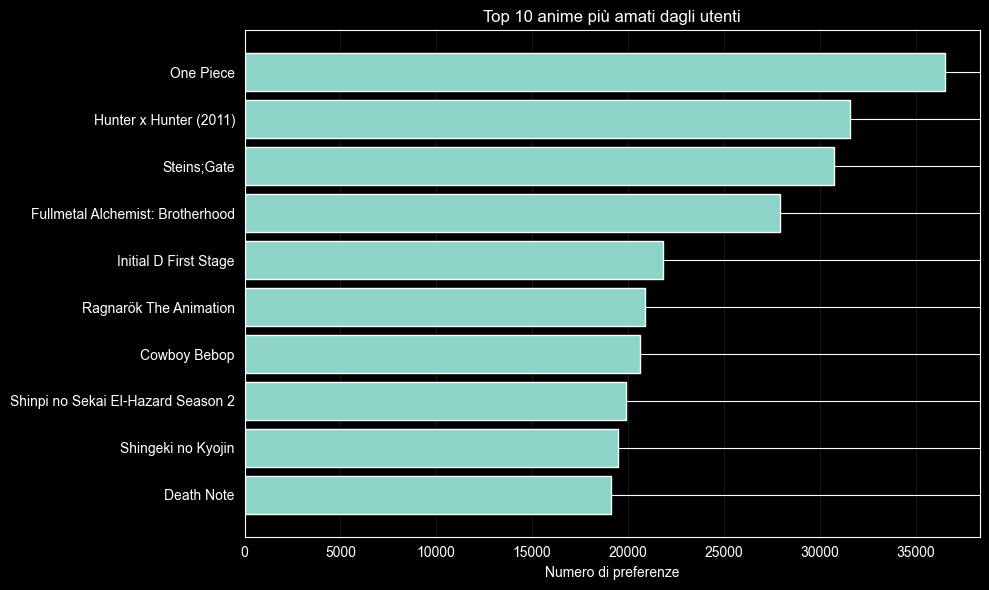

In [33]:
details = df_details.copy()
favs = df_favs.copy()
valid_mal_ids = details['mal_id'].unique()
filtered_favs = favs[favs['mal_id'].isin(valid_mal_ids)]

top_anime = (filtered_favs['mal_id'].value_counts().head(10).reset_index())
top_anime.columns = ['mal_id', 'fav_count']

top_anime = pd.merge(top_anime, details[['mal_id', 'title']], on='mal_id', how='inner')

# Sort for horizontal bar chart
top_anime = top_anime.sort_values('fav_count')

plt.figure(figsize=(10, 6))

plt.barh(top_anime['title'], top_anime['fav_count'])

plt.xlabel("Numero di preferenze")
plt.title("Top 10 anime più amati dagli utenti")
plt.grid(axis='x', alpha=0.1)

plt.tight_layout()
plt.show()

## One Piece: qualità percepita e popolarità tra gli utenti


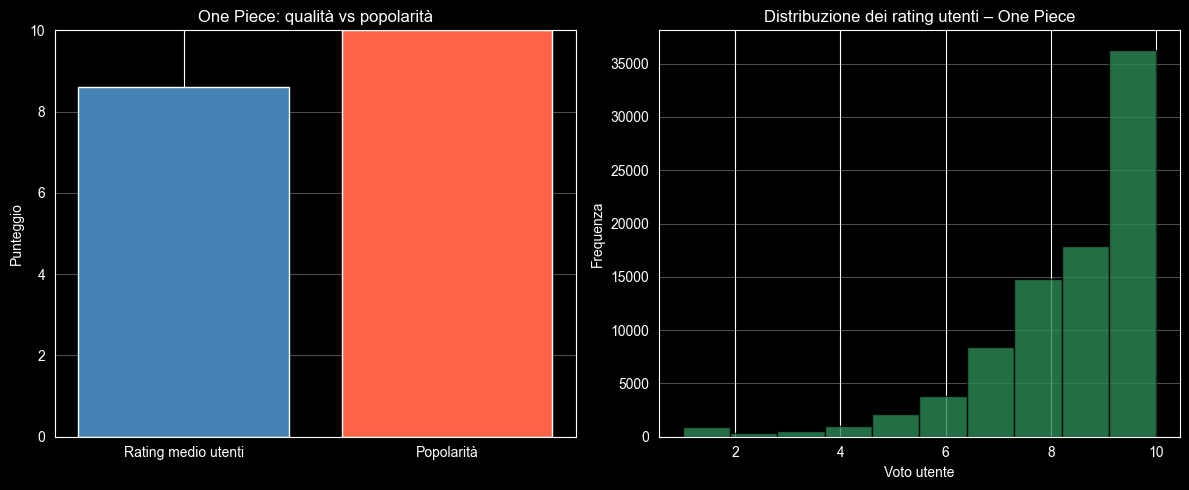

In [34]:
details = df_details.copy()
ratings = df_ratings.copy()
anime_title = "One Piece"
anime_row = details[details["title"] == anime_title]
mal_id = anime_row["mal_id"].iloc[0]
# Rimuoviamo score = 0 (utenti che non hanno votato)
anime_ratings = ratings[
    (ratings["anime_id"] == mal_id) &
    (ratings["score"] > 0)
    ]["score"]
avg_user_rating = anime_ratings.mean()
fav_count = favs[favs["mal_id"] == mal_id].shape[0]
# Normalizzazione favs su scala 0–10
fav_score_norm = (fav_count / favs["mal_id"].value_counts().max()) * 10
# Grafici
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
# Qualità vs Popolarità
labels = ["Rating medio utenti", "Popolarità"]
values = [avg_user_rating, fav_score_norm]

axes[0].bar(labels, values, color=["steelblue", "tomato"])
axes[0].set_ylim(0, 10)
axes[0].set_ylabel("Punteggio")
axes[0].set_title("One Piece: qualità vs popolarità")
axes[0].grid(axis="y", alpha=0.3)
# Distribuzione rating utenti
axes[1].hist(
    anime_ratings,
    bins=10,
    color="seagreen",
    edgecolor="black",
    alpha=0.8
)
axes[1].set_xlabel("Voto utente")
axes[1].set_ylabel("Frequenza")
axes[1].set_title("Distribuzione dei rating utenti – One Piece")
axes[1].grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()


Questo grafico analizza il caso di **One Piece**, mettendo a confronto la **qualità percepita dagli utenti** (rating medio) e la **popolarità**, misurata tramite il numero di preferenze (favs).

Il primo grafico evidenzia come One Piece presenti una popolarità estremamente elevata, normalizzata su una scala comparabile con il rating. Al contrario, il rating medio degli utenti risulta più moderato. Questo squilibrio suggerisce che la popolarità non dipende esclusivamente dal giudizio medio, ma anche da fattori come la longevità della serie, l’affezione emotiva del pubblico e l’impatto culturale nel tempo.

Il secondo grafico mostra la **distribuzione dei voti degli utenti**. Si osserva una forte concentrazione di voti alti (8–10), accompagnata però da una presenza significativa di voti bassi. Questo fenomeno è tipico delle opere molto popolari: attirano un pubblico ampio e diversificato, generando valutazioni più polarizzate.

Nel complesso, One Piece emerge come un esempio emblematico di come un anime possa essere **massicciamente seguito e amato**, pur non avendo un consenso uniforme sul piano della valutazione numerica.


## Gli anime con il rating più basso: cosa non ha convinto il pubblico

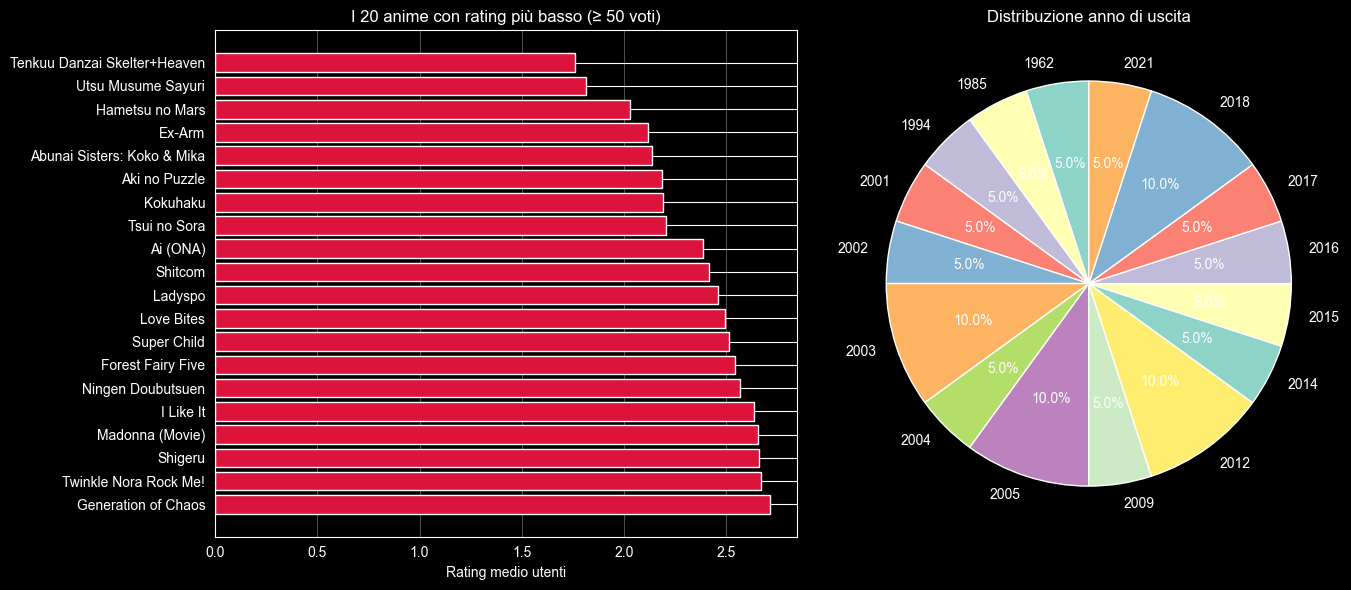

In [35]:
ratings_clean = df_ratings.copy()
ratings_clean = ratings_clean[ratings_clean["score"] > 0]

rating_stats = (
    ratings_clean
    .groupby("anime_id")
    .agg(
        avg_user_score=("score", "mean"),
        num_votes=("score", "count")
    )
    .reset_index()
)

# tieni solo anime con almeno 50 voti
rating_stats = rating_stats[rating_stats["num_votes"] >= 50]

anime_scores = pd.merge(
    rating_stats,
    df_details[["mal_id", "title", "year", "popularity"]],
    left_on="anime_id",
    right_on="mal_id",
    how="inner"
)

# filtro anno SENZA sovrascrivere tutto
anime_scores = anime_scores[
    (anime_scores["year"] >= 1917) &
    (anime_scores["year"] <= 2024)
]

worst_20 = (
    anime_scores
    .sort_values("avg_user_score", ascending=True)
    .head(20)
)

year_counts = worst_20["year"].value_counts().sort_index()

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

axes[0].barh(
    worst_20["title"],
    worst_20["avg_user_score"],
    color="crimson"
)
axes[0].invert_yaxis()
axes[0].set_xlabel("Rating medio utenti")
axes[0].set_title("I 20 anime con rating più basso (≥ 50 voti)")
axes[0].grid(axis="x", alpha=0.3)

axes[1].pie(
    year_counts.values,
    labels=year_counts.index,
    autopct="%1.1f%%",
    startangle=90
)
axes[1].set_title("Distribuzione anno di uscita")

plt.tight_layout()
plt.show()

# Anime

In [36]:
import pandas as pd
import numpy as np
import plotly.express as px

In [37]:
import pandas as pd
from matplotlib import pyplot as plt
import seaborn as sns
import numpy as np
import plotly.graph_objects as go
import ast
import plotly.express as px
import pycountry
from plotly.subplots import make_subplots


In [38]:
# load dataset
df_profiles = pd.read_csv("../../dataset/cleaned/profiles_cleaned.csv")
df_person_anime_works = pd.read_csv("../../dataset/cleaned/person_anime_works_cleaned.csv")
df_person_details = pd.read_csv("../../dataset/cleaned/person_details_cleaned.csv")
df_person_alternate_names = pd.read_csv("../../dataset/cleaned/person_alternate_names_cleaned.csv")



In [39]:
df_person_details["birthday"] = pd.to_datetime(df_person_details["birthday"], errors="coerce")
df_person_details["birth_year"] = df_person_details["birthday"].dt.year.astype("Int64")

df_person_details["favorites"] = pd.to_numeric(df_person_details["favorites"], errors="coerce")


## In quale aree del mondo gli anime sono maggiormente seguiti?


In [40]:
profiles = df_profiles.copy()

# pulizia base location
profiles["location"] = profiles["location"].astype("string").str.strip()
profiles.loc[
    profiles["location"].str.lower().isin(["", "nan", "none", "unknown"]),
    "location"
] = pd.NA
#estraggo paese
profiles["country_raw"] = profiles["location"].str.split(",").str[-1].str.strip()

#
country_fix = {
    "Usa": "United States",
    "US": "United States",
    "United States Of America": "United States",
    "UK": "United Kingdom",
    "England": "United Kingdom",
    "Scotland": "United Kingdom",
    "Russian Federation": "Russia",
    "Korea, Republic of": "South Korea",
    "Korea, Rep.": "South Korea",
    "Turkey": "Türkiye",
    "Turkiye": "Türkiye",
    "Türkiye": "Türkiye",

}
profiles["country_clean"] = profiles["country_raw"].replace(country_fix)
profiles["country_clean"] = profiles["country_clean"].where(
    profiles["country_clean"].isna(),
    profiles["country_clean"].str.replace(r"\s+", " ", regex=True).str.strip()
)

# ISO3 mapping
def to_iso3(x):
    if pd.isna(x):
        return pd.NA
    try:
        return pycountry.countries.lookup(x).alpha_3
    except Exception:
        return pd.NA

profiles["iso3"] = profiles["country_clean"].apply(to_iso3)

#controlli utili per verificare che ho preso tutti i paesi
u_total = profiles["username"].nunique()
unmapped = profiles.loc[profiles["iso3"].isna(), "username"].nunique()
coverage_iso3 = 1 - (unmapped / u_total)

print(f"Profiles coverage: {len(profiles):,} rows | {u_total:,} unique users")
print(f"Map coverage (ISO3): {coverage_iso3:.3f} | unmapped users: {unmapped}")


# conteggi
country_counts = (
    profiles.dropna(subset=["iso3"])
            .groupby("iso3")["username"]
            .nunique()
            .reset_index(name="n_users")
)
country_counts["log_users"] = np.log10(country_counts["n_users"] + 1)

# mappa
fig = px.choropleth(
    country_counts,
    locations="iso3",
    locationmode="ISO-3",
    color="log_users",
    hover_data={"n_users": True, "log_users": ":.2f"},
    title="Dove gli anime sono maggiormente seguiti?"
)
fig.update_layout(
    template="plotly_white",
    width=1100,
    height=600,
    coloraxis_colorbar=dict(title="log10(utenti)", tickformat=".1f")
)
fig.update_geos(showland=True, landcolor="lightgrey", showocean=True, oceancolor="#e6f2ff")
fig.show()

La mappa evidenzia paesi in cui il dataset registra una maggiore presenza di utenti appassionati di anime. L'intensità del colore cresce all'aumentare del numero di utenti unici per paese; l'uso della trasformazione log(n_users + 1) comprime le differenze estreme di valore e rende visibili anche paesi con valori più bassi.

#### A questo punto possiamo vedere come l'interesse per gli anime si è sviluppato durante il corso del tempo, considerando i paesi dove esse son maggiormente diffuse.

## Come si è evoluta nel tempo la crescita della community/nuovi utenti per gli anime nelle aree dove sono più concentrate?

In [41]:
df = df_profiles.copy()

# converto joined + extract year
profiles["joined"] = pd.to_datetime(profiles["joined"], errors="coerce")
profiles["joined_year"] = profiles["joined"].dt.year

#uso la stessa logica del grafico precedente
profiles["location"] = profiles["location"].astype("string").str.strip()
profiles.loc[
    profiles["location"].str.lower().isin(["", "nan", "none", "unknown"]),
    "location"
] = pd.NA

profiles["country_raw"] = profiles["location"].str.split(",").str[-1].str.strip()

country_fix = {
    "Usa": "United States",
    "US": "United States",
    "United States Of America": "United States",
    "UK": "United Kingdom",
    "England": "United Kingdom",
    "Scotland": "United Kingdom",
    "Russian Federation": "Russia",
    "Korea, Republic of": "South Korea",
    "Korea, Rep.": "South Korea",
    "Turkey": "Türkiye",
    "Turkiye": "Türkiye",
    "Türkiye": "Türkiye",
}
profiles["country_clean"] = profiles["country_raw"].replace(country_fix)

profiles["country_clean"] = profiles["country_clean"].where(
    profiles["country_clean"].isna(),
    profiles["country_clean"].str.replace(r"\s+", " ", regex=True).str.strip()
)

# filtri sugli anni non sensati
profiles = profiles.dropna(subset=["joined_year", "country_clean"])
profiles = profiles[profiles["joined_year"].between(1995, 2024)]

#top 6 countries
top_countries = (
    profiles.groupby("country_clean")["username"]
            .nunique()
            .sort_values(ascending=False)
            .head(6)
            .index
)

profiles_top = profiles[profiles["country_clean"].isin(top_countries)].copy()

# new users per year
trend = (
    profiles_top.groupby(["joined_year", "country_clean"])["username"]
                .nunique()
                .reset_index(name="n_users")
)


#line chart
fig = px.line(
    trend,
    x="joined_year",
    y="n_users",
    color="country_clean",
    markers=True,
    title="Crescita della community nel tempo: nuovi utenti registrati per anno (top paesi)"
)

fig.update_layout(
    template="plotly_white",
    width=1100, height=600,
    xaxis_title="Anno",
    yaxis_title="Nuovi utenti" ,
    legend_title_text = "Paese"
)

fig.show()


Il grafico mostra l'andamento dei nuovi utenti registrati ogni anno nei 6 paesi con la maggiore concentrazione di utenti nel dataset. Il Giappone e gli Stati Uniti offrono contributo dominante, mentre gli altri paesi hanno volumi più contenuti ma comunque trend simili.

#### E l'evoluzione a livello globale? Vediamo come si modifica a livello temporale ...

## Crescita della community nel tempo a livello globale

In [42]:
df = df_profiles.copy()
#convert joined to datetime and extract  year
df["joined"] = pd.to_datetime(df["joined"], errors="coerce")
df["joined_year"] = df["joined"].dt.year

users_per_year = (
    df.dropna(subset=["joined_year"])
      .assign(joined_year=lambda x: x["joined_year"].astype(int))
      .groupby("joined_year", observed=True)["username"]
      .nunique()
      .reset_index(name="new_users")
      .sort_values("joined_year")
)

users_per_year = users_per_year[users_per_year["joined_year"].between(2005, 2024)].copy()

#line chart
fig = px.line(
    users_per_year,
    x="joined_year",
    y="new_users",
    markers=True,
    title="Crescita della community nel tempo: nuovi utenti registrati per anno",
    labels={"joined_year": "Anno", "new_users": "Nuovi utenti"},
)
fig.update_layout(template="plotly_white", width=1100, height=600)
fig.show()

Il grafico mostra l’andamento dei nuovi utenti registrati ogni anno: si osserva una crescita nel tempo, con picchi marcati negli anni più recenti.

Dopo aver osservato la crescita della community nel tempo, analizziamo come sono composte le liste degli utenti, distinguendo  l'anno di registrazione, per capire se le abitudini di consumo variano tra utenti ‘vecchi’ e ‘nuovi’.

## Composizione delle liste per anno di iscrizione:

In [43]:
df = df_profiles.copy()

# anno iscrizione
df["joined"] = pd.to_datetime(df["joined"], errors="coerce")
df["joined_year"] = df["joined"].dt.year

# colonne di consumo
cols = ["watching", "completed", "on_hold", "dropped", "plan_to_watch"]
df[cols] = df[cols].apply(pd.to_numeric, errors="coerce").fillna(0)


# aggregazione per anno
consumption_time = (
    df.dropna(subset=["joined_year"])
      .assign(joined_year=lambda x: x["joined_year"].astype(int))
      .groupby("joined_year", observed=True)[cols]
      .sum()
      .reset_index()
      .sort_values("joined_year")
)
#periodo
consumption_time = consumption_time[consumption_time["joined_year"].between(1917, 2024)].copy()

#trasformo in percentuale, così da avere dati più omogenei
den = consumption_time[cols].sum(axis=1)
consumption_time = consumption_time[den > 0].copy()
den = consumption_time[cols].sum(axis=1)

consumption_pct = consumption_time.copy()
consumption_pct[cols] = consumption_pct[cols].div(den, axis=0) * 100

# righe controllo
print(f"joined_year coverage: {df['joined_year'].notna().mean():.3f}")
print(f"cohort share sums (min–max): {consumption_pct[cols].sum(axis=1).min():.1f}% – {consumption_pct[cols].sum(axis=1).max():.1f}%")


#grafico
consumption_long = consumption_pct.melt(
    id_vars="joined_year",
    value_vars=cols,
    var_name="status",
    value_name="share"
)
#ordine
status_order = ["completed", "plan_to_watch", "watching", "on_hold", "dropped"]

fig = px.area(
    consumption_long,
    x="joined_year",
    y="share",
    color="status",
    title="Composizione delle liste per coorte di iscrizione",
    labels={"joined_year": "Anno di iscrizione", "share": "Quota (%)", "status": "Status"},
    category_orders={"status": status_order}
)

fig.update_layout(template="plotly_white", width=1100, height=600)
fig.update_yaxes(ticksuffix="%", range=[0,100], dtick=10)
fig.update_traces(hovertemplate="Quota=%{y:.1f}%<br>Anno=%{x}<extra></extra>")
fig.show()

Il grafico mostra, per ogni coorte di iscrizione (anno di registrazione), la composizione percentuale delle liste degli utenti nei diversi status (watching, completed, on_hold, dropped, plan_to_watch). Le quote sommano a 100% per anno e permettono di confrontare come cambia la struttura delle liste tra coorti.

### Quanti anime sono state completate ogni anno (mi servono altri dati)?

Ci spostiamo ora nel mondo dell'industria anime, e in particolare sugli utenti che lavorano nell'industria anime

Prima di analizzare i ruoli più frequenti, stimiamo la scala del workforce osservato nel dataset: quante persone compaiono nei credits degli anime e quante relazioni persona–anime sono registrate. Successivamente identifichiamo i Top 10 ruoli e confrontiamo frequenza nei credits e notorietà (favorites come proxy di popolarità della persona).

## Dimensione del workforce osservato nei credits anime

In [44]:
works = df_person_anime_works.copy()
works["person_mal_id"] = pd.to_numeric(works["person_mal_id"], errors="coerce")
works["anime_mal_id"] = pd.to_numeric(works["anime_mal_id"], errors="coerce")
works = works.dropna(subset=["person_mal_id", "anime_mal_id"])

n_people = works["person_mal_id"].nunique()

fig = go.Figure()
fig.add_shape(
    type="circle",
    xref="paper", yref="paper",
    x0=0.18, y0=0.18, x1=0.82, y1=0.82,
    line=dict(color="#7fd6c2", width=10),
    fillcolor="rgba(0,0,0,0)"
)

fig.add_annotation(
    x=0.5, y=0.57, xref="paper", yref="paper",
    text=f"<b>{n_people:,}</b>",
    showarrow=False,
    font=dict(size=64, color="black")
)
fig.add_annotation(
    x=0.5, y=0.38, xref="paper", yref="paper",
    text="persone uniche nei credits",
    showarrow=False,
    font=dict(size=16, color="black")
)

fig.update_layout(
    template="plotly_white",
    width=850, height=320,
    margin=dict(l=20, r=20, t=60, b=20),
    title=dict(text="Quante persone compaiono nei credits?", x=0.01),
)

fig.update_xaxes(visible=False)
fig.update_yaxes(visible=False)
fig.show()

## Ma quali sono i ruoli più diffusi e quali hanno maggiore notorietà?

In [45]:
works = df_person_anime_works.copy()
details = df_person_details[["person_mal_id", "favorites"]].copy()

# ruolo
works["position_norm"] = (
    works["position"].astype("string")
    .str.replace(r"\s*\(ep\s*\d+\)\s*$", "", regex=True)
    .str.replace(r"\s+", " ", regex=True)
    .str.strip()
)
works.loc[works["position_norm"].str.lower().isin(["", "nan", "none", "unknown"]), "position_norm"] = pd.NA

# conteggi occorrenze
role_counts = works["position_norm"].dropna().value_counts().reset_index()
role_counts.columns = ["role", "occurrences"]

top10 = role_counts.head(10).copy()
total_occ = role_counts["occurrences"].sum()
top10["occ_pct"] = top10["occurrences"] / total_occ * 100

# favorites
details["person_mal_id"] = pd.to_numeric(details["person_mal_id"], errors="coerce").astype("Int64")
details["favorites"] = pd.to_numeric(details["favorites"], errors="coerce").fillna(0)
details = details.drop_duplicates(subset=["person_mal_id"])

# persone uniche per ruolo + merge favorites
role_people = (
    works.loc[works["position_norm"].isin(top10["role"]), ["person_mal_id", "position_norm"]]
    .dropna(subset=["person_mal_id", "position_norm"])
    .drop_duplicates()
    .rename(columns={"position_norm": "role"})
).merge(details, on="person_mal_id", how="left")

role_people["favorites"] = role_people["favorites"].fillna(0)

fav_stats = (
    role_people.groupby("role", observed=True)["favorites"]
    .agg(
        people="count",
        share_nonzero=lambda s: (s > 0).mean() * 100,
        median_fav_pos=lambda s: s[s > 0].median(),
    )
    .reset_index()
)
fav_stats["median_fav_pos"] = fav_stats["median_fav_pos"].fillna(0)

top10 = top10.merge(fav_stats, on="role", how="left")
role_order = top10.sort_values("occurrences", ascending=False)["role"].tolist()
top10 = top10.set_index("role").loc[role_order].reset_index()  # riallinea tutto in modo sicuro

role_color_map = {
    "Key Animation": "#7fd6c2",
    "Animation Director": "#fff7a8",
    "Producer": "#c7c2e0",
    "In-Between Animation": "#ff7f7a",
    "2nd Key Animation": "#7fb3d5",
    "Episode Director": "#f5b041",
    "Planning": "#a8df65",
    "Original Creator": "#f7b6d2",
    "Music": "#d9d9d9",
    "Director": "#af7ac5",
}
occ_colors = [role_color_map.get(r, "#7fd6c2") for r in top10["role"]]


y = top10["role"].tolist()

text_occ = top10["occ_pct"].round(1).astype(str) + "%"
text_fav = top10["median_fav_pos"].round(0).astype(int).astype(str)

custom = np.stack(
    [top10["occurrences"], top10["people"], top10["share_nonzero"], top10["median_fav_pos"]],
    axis=1
)

hover = (
    "Ruolo=%{y}<br>"
    "Occorrenze=%{customdata[0]}<br>"
    "Persone (nel ruolo)=%{customdata[1]}<br>"
    "% con favorites>0=%{customdata[2]:.1f}%<br>"
    "Mediana favorites (>0)=%{customdata[3]:.0f}"
    "<extra></extra>"
)

fig = go.Figure()

# Occorrenze
fig.add_trace(go.Bar(
    x=top10["occurrences"], y=y, orientation="h",
    text=text_occ, textposition="outside",
    marker=dict(color=occ_colors),
    customdata=custom, hovertemplate=hover,
    visible=True
))

# Favorites (colore unico)
fig.add_trace(go.Bar(
    x=top10["median_fav_pos"],
    y=y,
    orientation="h",
    text=text_fav,
    textposition="outside",
    marker=dict(color=occ_colors),
    customdata=custom,
    hovertemplate=hover,
    visible=False
))

fig.update_layout(
    template="plotly_dark",
    width=1100, height=650,
    showlegend=False,
    title="Quali sono i ruoli più diffusi nell'industria degli anime (Top 10)?",
    xaxis_title="Numero di occorrenze",
    yaxis_title="Ruolo",
    yaxis=dict(categoryorder="array", categoryarray=role_order),
    updatemenus=[dict(
        type="buttons",
        direction="right",
        x=0.01, y=1.07,
        showactive=True,
        bgcolor="rgba(255,255,255,0.92)",
        bordercolor="rgba(0,0,0,0.25)",
        font=dict(color="black"),
        buttons=[
            dict(
                label="Ruoli più diffusi (occorrenze)",
                method="update",
                args=[{"visible": [True, False]},
                      {"title.text": "Quali sono i ruoli più diffusi nell'industria degli anime (Top 10)?",
                "xaxis.title.text": "Numero di occorrenze",}],
            ),
            dict(
                label="Notorietà (mediana favorites > 0)",
                method="update",
                args=[{"visible": [False, True]},
                      {"title.text": "Notorietà per ruolo: sui Top 10 ruoli",
                "xaxis.title.text": "Mediana favorites" }], # solo >0
            ),
        ],
    )],
)

fig.show()

Abbiamo analizzato i 10 ruoli più diffusi nell'industria anime e la loro notorietà (ovvero quali e da quanti sono stati selezionati come preferiti)

## Dove sono localizzate le persone nei credits?

IDEA FAI UNA MAPPA DOVE EVIDENZI DELLO STESSO COLORE DOVE SONO DIFFUSI LE PERS DI CREDITS, SENZA DIRE QUANTE PER OGNI PAESE E DI FIANCO METTI BAR CHART CON QUANTE PER OGNI PAESE

In [46]:
# country da relevant_location
details = df_person_details.copy()

details["country"] = (
    details["relevant_location"]
    .astype("string")
    .str.strip()
    .str.split(",")
    .str[-1]
    .str.strip()
)

country_fix = {
    "Usa": "United States",
    "USA": "United States",
    "United States Of America": "United States",
    "UK": "United Kingdom",
    "U.K.": "United Kingdom",
    "England": "United Kingdom",
    "Scotland": "United Kingdom",
    "Russian Federation": "Russia",
    "Korea, Republic of": "South Korea",
    "Korea, Rep.": "South Korea",
    "Viet Nam": "Vietnam",
    "Türkiye": "Turkey",
    "Turkiye": "Turkey",
}
details["country"] = details["country"].replace(country_fix)

details["country"] = details["country"].where(
    details["country"].isna(),
    details["country"].str.replace(r"\s+", " ", regex=True).str.strip().str.title()
)

# persone uniche x paese
country_counts = (
    details.dropna(subset=["country"])
           .groupby("country")["person_mal_id"]
           .nunique()
           .reset_index(name="n_people")
)

# controllo
valid_countries = set(px.data.gapminder()["country"].unique())

unmapped = country_counts.loc[~country_counts["country"].isin(valid_countries)].copy()
unmapped_people = unmapped["n_people"].sum()
total_people = country_counts["n_people"].sum()

print(f"Paesi presenti nei dati: {len(country_counts)}")
print(f"Paesi NON mappabili (plotly): {len(unmapped)} | persone non mappate: {unmapped_people:,} | coverage persone: {1 - unmapped_people/total_people:.3f}")
print("Esempi paesi non mappati:", unmapped["country"].head(15).tolist())

# present
present_df = country_counts[["country"]].copy()
present_df["present"] = 1

# mappa + bar
fig = make_subplots(
    rows=1, cols=2,
    specs=[[{"type": "choropleth"}, {"type": "bar"}]],
    column_widths=[0.58, 0.42],
    subplot_titles=[
        "Paesi con almeno una persona nei credits (presenza)",
        "Numero di persone per paese"
    ]
)

fig.add_trace(
    go.Choropleth(
        locations=present_df["country"],
        locationmode="country names",
        z=present_df["present"],
        colorscale=[(0, "#ffffff"), (1, "#7fd6c2")],
        showscale=False,
        marker_line_color="lightgrey",
        marker_line_width=0.5,
        hovertemplate="Paese=%{location}<extra></extra>"
    ),
    row=1, col=1
)

# Bar chart paesi
bar_df = country_counts.sort_values("n_people", ascending=False).copy()
bar_df["share"] = bar_df["n_people"] / bar_df["n_people"].sum() * 100

fig.add_trace(
    go.Bar(
        x=bar_df["n_people"],
        y=bar_df["country"],
        orientation="h",
        marker_color="#7fd6c2",
        text=(bar_df["share"].round(1).astype(str) + "%"),
        textposition="outside",
        hovertemplate="Paese=%{y}<br>Persone=%{x:,}<br>Quota=%{text}<extra></extra>"
    ),
    row=1, col=2
)

height = min(2000, max(650, 18 * len(bar_df) + 250))  # adatta altezza se ci sono molti paesi

fig.update_layout(
    template="plotly_white",
    width=1200,
    height=height,
    title=dict(text="Distribuzione geografica delle persone nei credits (relevant_location)", x=0.01),
    margin=dict(t=80, l=30, r=30, b=30),
)

fig.update_geos(
    showland=True, landcolor="white",
    showcountries=True, countrycolor="lightgrey",
    showocean=True, oceancolor="#f5f7fb"
)

fig.update_yaxes(autorange="reversed", row=1, col=2)
fig.update_xaxes(title_text="Persone uniche", row=1, col=2)

fig.show()

Grafico che mostra dove abitano le persone che lavorano nell'industria anime

## Quali sono le generazioni più diffuse nell'industria anime?

In [47]:
# prendo person_mal_id
works_people = (
    df_person_anime_works[["person_mal_id"]]
    .copy()
)
#converto in numerico e tolgo righe mancanti o duplicati (controllo ch eho aggiunto per sicurezza)
works_people = df_person_anime_works[["person_mal_id"]].copy()
works_people["person_mal_id"] = pd.to_numeric(works_people["person_mal_id"], errors="coerce").astype("Int64")
works_people = works_people.dropna(subset=["person_mal_id"]).drop_duplicates()

# recupero anni di nascita da details
details_birth = df_person_details[["person_mal_id", "birthday"]].copy()
details_birth["person_mal_id"] = pd.to_numeric(details_birth["person_mal_id"], errors="coerce").astype("Int64")
details_birth["birthday"] = pd.to_datetime(details_birth["birthday"], errors="coerce", utc=True)
details_birth["birth_year"] = details_birth["birthday"].dt.year.astype("Int64")

# filtro anni (prima di 1900 e dopo 2024 gli anni li considero 'non palusibili' per evitare dati strani)
details_birth.loc[~details_birth["birth_year"].between(1900, 2024), "birth_year"] = pd.NA
details_birth = details_birth.drop_duplicates(subset=["person_mal_id"])

staff = works_people.merge(details_birth[["person_mal_id", "birth_year"]], on="person_mal_id", how="left")

#controlli
tot_people = staff["person_mal_id"].nunique()
known_people = staff.loc[staff["birth_year"].notna(), "person_mal_id"].nunique()
print(f"Staff in credits: {tot_people:,} unique people")
print(f"Birth year coverage: {known_people/tot_people:.3f} ({known_people:,}/{tot_people:,})")


# generazioni
labels = ["Silent Generation", "Boomers", "Gen X", "Millennials", "Gen Z", "Gen Alpha"]
staff["generation"] = pd.cut(
    staff["birth_year"],
    bins=[-np.inf, 1945, 1964, 1980, 1996, 2012, 2024],
    labels=labels,
    right=True
)
gen_counts = (
    staff.dropna(subset=["generation"])
         .groupby("generation", observed=True)["person_mal_id"]
         .nunique()
         .reset_index(name="count")
)

gen_counts["generation"] = pd.Categorical(gen_counts["generation"], categories=labels, ordered=True)
gen_counts = gen_counts.sort_values("generation")
gen_counts["share"] = gen_counts["count"] / gen_counts["count"].sum() * 100

color_map = {
    "Silent Generation": "#A0AEC0",
    "Boomers": "#F6AD55",
    "Gen X": "#63B3ED",
    "Millennials": "#68D391",
    "Gen Z": "#FC8181",
    "Gen Alpha": "#B794F4",
}

fig = px.bar(
    gen_counts,
    x="generation",
    y="count",
    color="generation",
    color_discrete_map=color_map,
    text=gen_counts["share"].round(1).astype(str) + "%",
    title="Quali generazioni sono più diffuse tra le persone che fanno parte dell’industria anime?",
    labels={"count": "Numero di persone", "generation": "Generazione"},
)
fig.update_layout(template="plotly_white", width=1100, height=600, showlegend=False)
fig.update_traces(textposition="outside")
fig.update_yaxes(rangemode="tozero")
fig.show()

Il grafico mostra la distribuzione delle generazioni tra le persone presenti nello staff, ogni barra evidenzia il numero di persone uniche per generazione, con la percentuale calcolata sul sottoinsieme per cui l'anno di nascita è disponibile.